<a href="https://colab.research.google.com/github/princedandge9-alt/Sales-Data-Filter-Report-Engine/blob/main/Sales_Data_Filter_Report_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 3: Sales Data Filter & Report Engine


**Simulate a year of sales for 10 stores and build a query engine that filters records and generates reports using NumPy.**

## Objectives:
- Simulate sales for 10 stores and 12 months.
- Use 2D slicing for quarters and stores.
- Use boolean masking with &, |, ~.
- Use fancy indexing and find the best 3 months.
- Generate monthly and store-wise reports.


In [ ]:
import numpy as np

np.random.seed(42)

months = np.arange(1, 13)
month_names = np.array(['Jan','Feb','Mar','Apr','May','Jun',
                        'Jul','Aug','Sep','Oct','Nov','Dec'])


##10 stores x 12 months, sales in thousands

In [ ]:
sales = np.random.randint(80, 251, size=(10, 12))

stores = np.array([f'Store_{i}' for i in range(1, 11)])

print("Sales shape:", sales.shape)
print("Sales data:")
print(sales)

Sales shape: (10, 12)
Sales data:
[[182 172  94 186 151 100 182 201 154 167 196 179]
 [183 231 210 229 132  81 167 237 117 209 100 240]
 [137 101 168 128 138 249  94 130 187 134 143 210]
 [130 214 100 152 246  97 211 168 139  93  88 169]
 [132 209 163 171 190  87 114 160 243 129 183 211]
 [ 81 213 133 185  83 133 225 123 241  93 174 127]
 [ 94 119 161 190 132 103 233 203 120 236  94 124]
 [144 168 150  88 167 208 215 142 218 160 215 242]
 [242 112 202  84 120 107 214 151  91 241 112 127]
 [230 141 116 178 183 114 180 210  80  84 221 182]]


##Basic Statistics

In [ ]:
print("Total sales:", sales.sum(), "thousand")
print("Average sale:", round(sales.mean(), 2), "thousand")
print("Maximum sale:", sales.max(), "thousand")
print("Minimum sale:", sales.min(), "thousand")


Total sales: 19177 thousand
Average sale: 159.81 thousand
Maximum sale: 249 thousand
Minimum sale: 80 thousand


## 2D Slicing: Quarters and Individual Stores

In [ ]:
Q1 = sales[:, 0:3]
Q2 = sales[:, 3:6]
Q3 = sales[:, 6:9]
Q4 = sales[:, 9:12]

print("Q1 shape:", Q1.shape)
print("Q2 shape:", Q2.shape)
print("Q3 shape:", Q3.shape)
print("Q4 shape:", Q4.shape)

print("\nStore 1:", sales[0, :])
print("Store 5:", sales[4, :])


Q1 shape: (10, 3)
Q2 shape: (10, 3)
Q3 shape: (10, 3)
Q4 shape: (10, 3)

Store 1: [182 172  94 186 151 100 182 201 154 167 196 179]
Store 5: [132 209 163 171 190  87 114 160 243 129 183 211]


###Boolean Masking / Query Engine

In [ ]:
monthly_total = sales.sum(axis=0)
target = 1500

# Months with total sales greater than target
months_above_target = month_names[monthly_total > target]
print("Months above target:", months_above_target)

# Stores below overall average
store_total = sales.sum(axis=1)
store_average = store_total.mean()
stores_below_average = stores[store_total < store_average]
print("Stores below average:", stores_below_average)

# AND condition
and_query = month_names[(monthly_total > 1500) & (monthly_total < 1900)]
print("Months between 1500 and 1900:", and_query)

# OR condition
or_query = month_names[(monthly_total > 1700) | (monthly_total < 1200)]
print("Months above 1700 OR below 1200:", or_query)

# NOT condition
not_query = month_names[~(monthly_total > 1500)]
print("Months NOT above 1500:", not_query)


Months above target: ['Jan' 'Feb' 'Apr' 'May' 'Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec']
Stores below average: ['Store_3' 'Store_4' 'Store_6' 'Store_7' 'Store_9']
Months between 1500 and 1900: ['Jan' 'Feb' 'Apr' 'May' 'Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec']
Months above 1700 OR below 1200: ['Jul' 'Aug' 'Dec']
Months NOT above 1500: ['Mar' 'Jun']


##Fancy Indexing

In [ ]:
# Select stores [1, 4, 7] using zero-based Python row indexes
selected_indices = [1, 4, 7]
selected_stores = sales[selected_indices, :]

print("Selected stores:", stores[selected_indices])
print(selected_stores)

# Best 3 months
best_3_indices = np.argsort(monthly_total)[-3:][::-1]
best_3_months = month_names[best_3_indices]
best_3_sales = monthly_total[best_3_indices]

print("\nBest 3 months:", best_3_months)
print("Sales:", best_3_sales)


Selected stores: ['Store_2' 'Store_5' 'Store_8']
[[183 231 210 229 132  81 167 237 117 209 100 240]
 [132 209 163 171 190  87 114 160 243 129 183 211]
 [144 168 150  88 167 208 215 142 218 160 215 242]]

Best 3 months: ['Jul' 'Dec' 'Aug']
Sales: [1835 1811 1725]


##Growth Targets using np.linspace

In [ ]:
growth_targets = np.linspace(1400, 1800, 12)

target_mask = monthly_total >= growth_targets

print("Growth targets:")
print(np.round(growth_targets, 2))

print("\nMonths meeting growth target:")
print(month_names[target_mask])

print("\nMonths below growth target:")
print(month_names[~target_mask])


Growth targets:
[1400.   1436.36 1472.73 1509.09 1545.45 1581.82 1618.18 1654.55 1690.91
 1727.27 1763.64 1800.  ]

Months meeting growth target:
['Jan' 'Feb' 'Mar' 'Apr' 'Jul' 'Aug' 'Dec']

Months below growth target:
['May' 'Jun' 'Sep' 'Oct' 'Nov']


##Monthly Report

In [ ]:
print("=" * 60)
print("MONTHLY SALES REPORT")
print("=" * 60)
print("{:<8}{:>10}{:>12}{:>12}".format(
    "Month", "Sales", "Target", "Status"))
print("-" * 60)

for i in range(12):
    status = "Achieved" if monthly_total[i] >= growth_targets[i] else "Below"
    print("{:<8}{:>10}{:>12.2f}{:>12}".format(
        month_names[i], monthly_total[i], growth_targets[i], status))


MONTHLY SALES REPORT
Month        Sales      Target      Status
------------------------------------------------------------
Jan           1555     1400.00    Achieved
Feb           1680     1436.36    Achieved
Mar           1497     1472.73    Achieved
Apr           1591     1509.09    Achieved
May           1542     1545.45       Below
Jun           1279     1581.82       Below
Jul           1835     1618.18    Achieved
Aug           1725     1654.55    Achieved
Sep           1590     1690.91       Below
Oct           1546     1727.27       Below
Nov           1526     1763.64       Below
Dec           1811     1800.00    Achieved


##Store-wise Report

In [ ]:
print("=" * 55)
print("STORE-WISE SALES REPORT")
print("=" * 55)
print("{:<12}{:>12}{:>12}{:>12}".format(
    "Store", "Total", "Average", "Status"))
print("-" * 55)

for i in range(10):
    status = "Above Avg" if store_total[i] >= store_average else "Below Avg"
    print("{:<12}{:>12}{:>12.2f}{:>12}".format(
        stores[i], store_total[i], sales[i].mean(), status))

STORE-WISE SALES REPORT
Store              Total     Average      Status
-------------------------------------------------------
Store_1             1964      163.67   Above Avg
Store_2             2136      178.00   Above Avg
Store_3             1819      151.58   Below Avg
Store_4             1807      150.58   Below Avg
Store_5             1992      166.00   Above Avg
Store_6             1811      150.92   Below Avg
Store_7             1809      150.75   Below Avg
Store_8             2117      176.42   Above Avg
Store_9             1803      150.25   Below Avg
Store_10            1919      159.92   Above Avg


# **Graphical Reports:**

##Monthly Sales vs Growth Target —> Line Graph

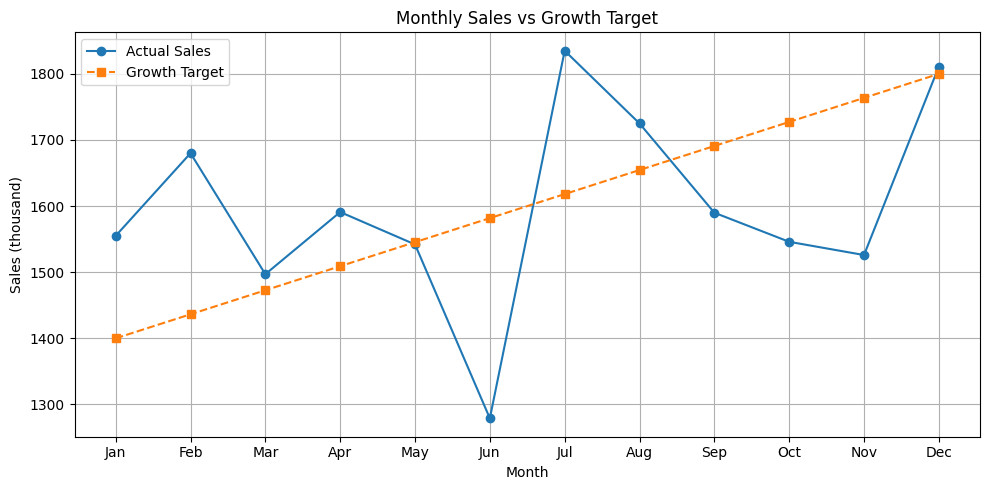

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(month_names, monthly_total,
         marker='o', label='Actual Sales')

plt.plot(month_names, growth_targets,
         marker='s', linestyle='--',
         label='Growth Target')

plt.title('Monthly Sales vs Growth Target')
plt.xlabel('Month')
plt.ylabel('Sales (thousand)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

##Store-wise Sales —> Bar Graph

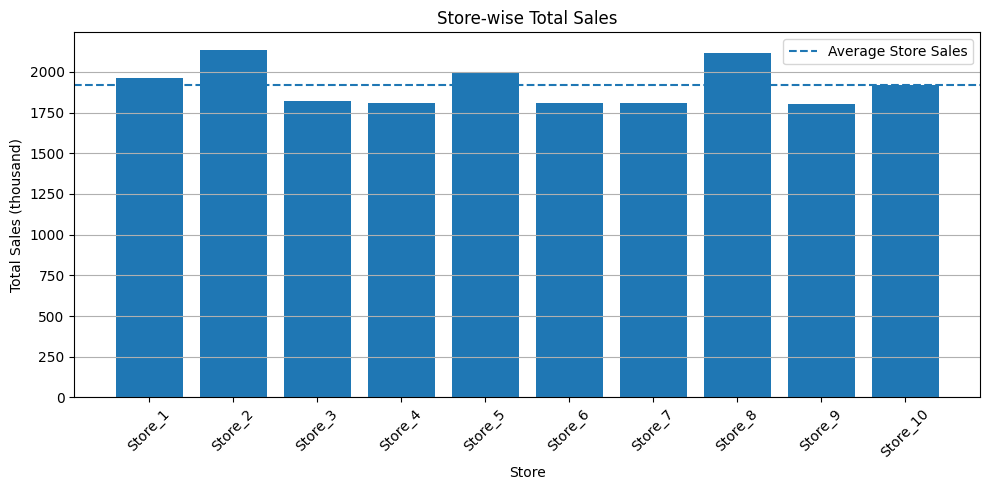

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(stores, store_total)
plt.axhline(store_average,
            linestyle='--',
            label='Average Store Sales')

plt.title('Store-wise Total Sales')
plt.xlabel('Store')
plt.ylabel('Total Sales (thousand)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

##Quarterly Sales —> Pie Chart


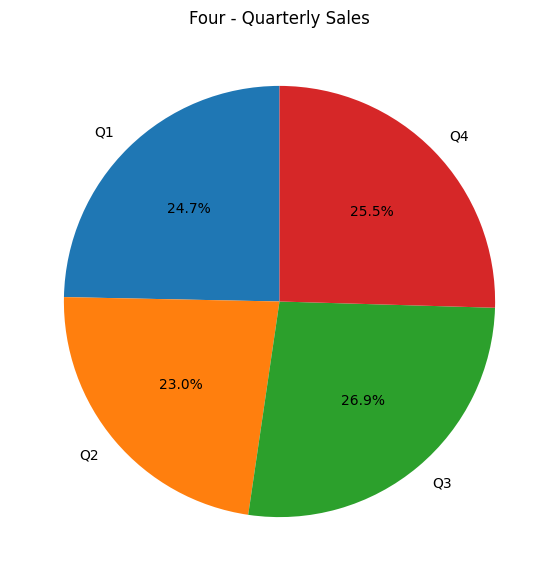

In [ ]:
import matplotlib.pyplot as plt

# Define quarters and calculate total sales for each
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
quarter_totals = [Q1.sum(), Q2.sum(), Q3.sum(), Q4.sum()]

plt.figure(figsize=(7, 7))

plt.pie(
    quarter_totals,
    labels=quarters,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Four - Quarterly Sales')

plt.show()

##Top 3 Sales Months

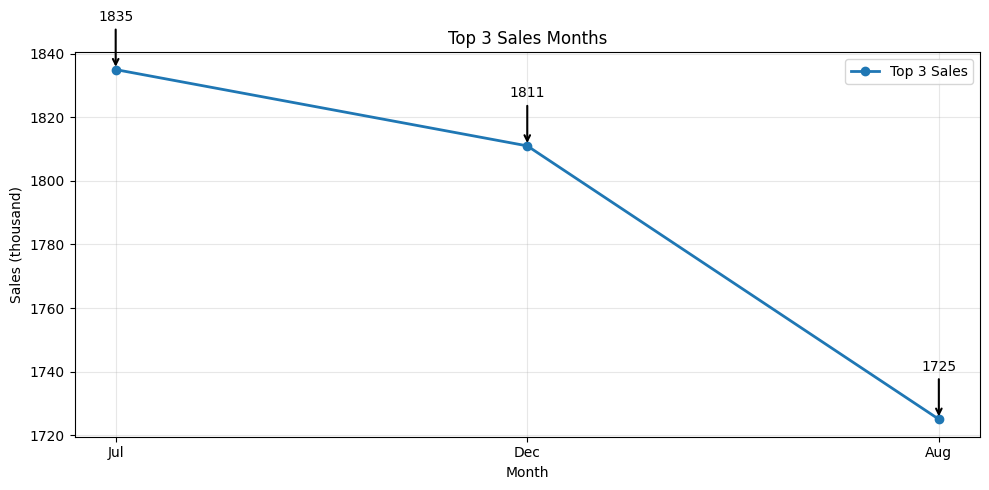

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    best_3_months,
    best_3_sales,
    marker='o',
    linewidth=2,
    label='Top 3 Sales'
)

for i in range(len(best_3_months)):
    plt.annotate(
        f'{best_3_sales[i]}',
        xy=(best_3_months[i], best_3_sales[i]),
        xytext=(0, 35),
        textcoords='offset points',
        ha='center',
        arrowprops=dict(
            arrowstyle='->',
            linewidth=1.5
        )
    )

plt.title('Top 3 Sales Months')
plt.xlabel('Month')
plt.ylabel('Sales (thousand)')

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

##Growth Target vs Actual Total Sales

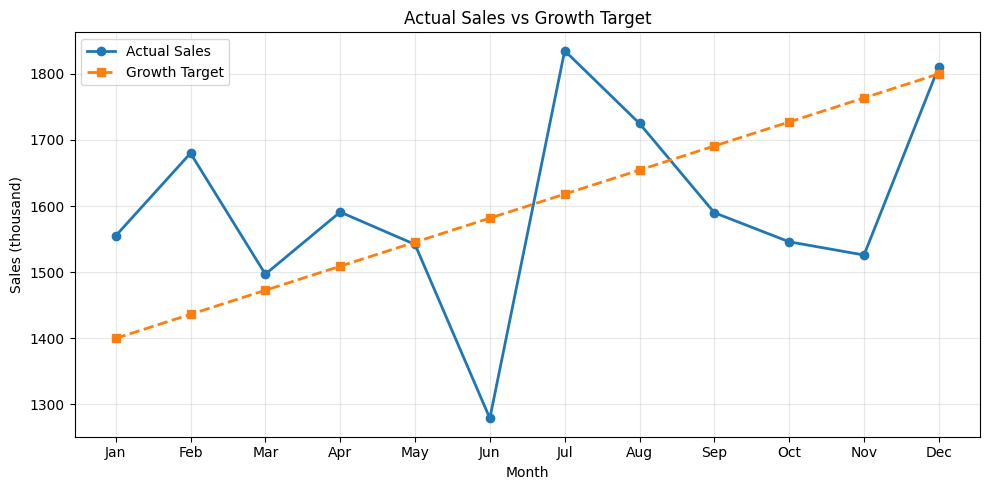

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    month_names,
    monthly_total,
    marker='o',
    linewidth=2,
    label='Actual Sales'
)

plt.plot(
    month_names,
    growth_targets,
    marker='s',
    linestyle='--',
    linewidth=2,
    label='Growth Target'
)

plt.title('Actual Sales vs Growth Target')
plt.xlabel('Month')
plt.ylabel('Sales (thousand)')

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##**Conclusion**
np.arange, np.linspace, np.random, reshape, boolean
masking (&, |, ~), fancy indexing, 2D slicing.